In [4]:
import subprocess
import sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "matplotlib"])

0

### Cargar Dataset

In [ ]:
import numpy as np
import pandas as pd

df_raw = pd.read_csv(r'C:\Users\ASUS\Documents\Repositorios\ml-zoomcamp\data\car_fuel_efficiency_2026.csv')
df_raw.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


### Filtrar columnas

In [12]:
cols = ['engine_displacement', 'horsepower', 'vehicle_weight', 
        'model_year', 'fuel_efficiency_mpg']
df = df_raw[cols].copy()
df.shape

(10000, 5)

### EDA

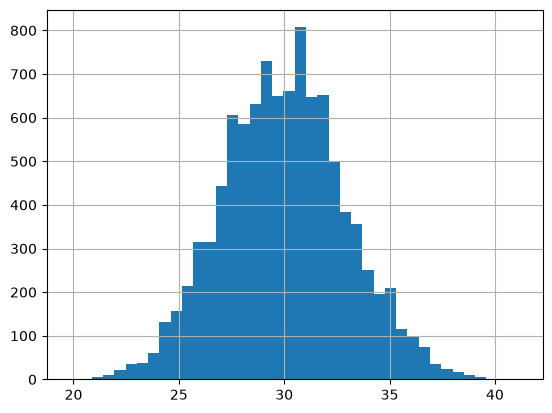

In [14]:
df['fuel_efficiency_mpg'].hist(bins=40)
plt.show()

#### Q1: columna con nulos

In [ ]:
print(df.isnull().sum())


engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64


#### Q2: mediana de horsepower

In [ ]:
print("Mediana horsepower:", df['horsepower'].median())

Mediana horsepower: 254.0


### Split del dataset

In [17]:
n = len(df)
n_val   = int(n * 0.2)
n_test  = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
df_val   = df.iloc[idx[n_train:n_train+n_val]].reset_index(drop=True)
df_test  = df.iloc[idx[n_train+n_val:]].reset_index(drop=True)

print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

Train: 6000 | Val: 2000 | Test: 2000


In [18]:
target   = 'fuel_efficiency_mpg'
features = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']

def rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def train_lr(X, y, r=0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T @ X + r * np.eye(X.shape[1])
    w = np.linalg.inv(XTX) @ X.T @ y
    return w[0], w[1:]

def predict(w0, w, X):
    return w0 + X @ w

#### Q3: fillna(0) vs fillna(mean)

In [19]:
# Media calculada SOLO con train
mean_val = df_train['horsepower'].mean()  # cambia 'horsepower' si Q1 es otra columna

for label, val in [('0', 0), ('mean', mean_val)]:
    X_tr = df_train[features].fillna(val).values
    X_v  = df_val[features].fillna(val).values
    
    w0, w = train_lr(X_tr, df_train[target].values)
    score = rmse(df_val[target].values, predict(w0, w, X_v))
    
    print(f"fillna({label}): RMSE = {round(score, 3)}")

fillna(0): RMSE = 2.205
fillna(mean): RMSE = 2.202


#### Q4: regularización

In [20]:
X_tr = df_train[features].fillna(0).values
X_v  = df_val[features].fillna(0).values

print("=== Q4: Regularización ===")
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_lr(X_tr, df_train[target].values, r=r)
    score = rmse(df_val[target].values, predict(w0, w, X_v))
    print(f"r={r:>6}: RMSE = {round(score, 4)}")

=== Q4: Regularización ===
r=     0: RMSE = 2.2053
r=  0.01: RMSE = 2.2058
r=   0.1: RMSE = 2.2241
r=     1: RMSE = 2.3492
r=     5: RMSE = 2.4094
r=    10: RMSE = 2.4195
r=   100: RMSE = 2.4292


#### Q5: estabilidad con semillas

In [21]:
scores = []

for seed in range(10):  # 0 al 9
    np.random.seed(seed)
    idx2 = np.arange(n)
    np.random.shuffle(idx2)
    
    dtr = df.iloc[idx2[:n_train]]
    dv  = df.iloc[idx2[n_train:n_train+n_val]]
    
    X_tr2 = dtr[features].fillna(0).values
    X_v2  = dv[features].fillna(0).values
    
    w0, w = train_lr(X_tr2, dtr[target].values)
    score = rmse(dv[target].values, predict(w0, w, X_v2))
    scores.append(score)
    print(f"seed={seed}: RMSE={round(score, 3)}")

print(f"\n=== Q5: STD = {round(np.std(scores), 3)} ===")

seed=0: RMSE=2.239
seed=1: RMSE=2.202
seed=2: RMSE=2.163
seed=3: RMSE=2.204
seed=4: RMSE=2.202
seed=5: RMSE=2.246
seed=6: RMSE=2.27
seed=7: RMSE=2.191
seed=8: RMSE=2.217
seed=9: RMSE=2.207

=== Q5: STD = 0.029 ===


#### Q6: seed 9, modelo final en test

In [22]:
np.random.seed(9)
idx3 = np.arange(n)
np.random.shuffle(idx3)

dtr9 = df.iloc[idx3[:n_train]]
dv9  = df.iloc[idx3[n_train:n_train+n_val]]
dte9 = df.iloc[idx3[n_train+n_val:]]

# Combinar train + val
df_full = pd.concat([dtr9, dv9])

X_full = df_full[features].fillna(0).values
X_te9  = dte9[features].fillna(0).values

w0, w = train_lr(X_full, df_full[target].values, r=0.001)
score = rmse(dte9[target].values, predict(w0, w, X_te9))

print(f"=== Q6: RMSE test = {round(score, 3)} ===")

=== Q6: RMSE test = 2.236 ===
